# Tarea 3 - Calidad de vino tinto: regresión vs. clasificación

**Dataset:** *Wine Quality* (variedad tinta), UCI Machine Learning Repository.
Archivo `winequality-red.csv`: 1 599 vinos, 11 variables fisicoquímicas y una
variable objetivo `quality` (puntaje entero de 0 a 10, aquí entre 3 y 8).

**Preguntas de la tarea**

1. **Regresión.** Predecir `quality` con una regresión lineal. Reportar RMSE y R^2 en
   prueba y compararlos con el modelo trivial de predecir siempre el promedio.
2. **Clasificación.** Definir `bueno = quality >= 7`, ajustar *la misma* regresión
   lineal a esa columna y clasificar como *bueno* si `y_hat >= 0.5`. Reportar el
   porcentaje de aciertos en prueba, el de predecir siempre "no bueno", y cuántas
   predicciones quedan fuera de `[0, 1]`.
3. **Conclusión.** Qué cambia entre los dos problemas y qué le falla a la recta como
   clasificador.

En ambos casos se usa la misma partición **80 / 20** con `random_state=42`.

Se fija la semilla global y un backend de matplotlib sin ventana, para que el
notebook sea reproducible y se pueda ejecutar de forma no interactiva.

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, confusion_matrix, precision_score,
                             recall_score, f1_score)

SEED = 42
np.random.seed(SEED)


### 0.1 Carga del dataset

Se usa el archivo local `winequality-red.csv` (idéntico al publicado por UCI). Si no
estuviera presente, la celda lo descarga del repositorio de UCI; el archivo usa `;`
como separador y punto decimal, y en algunas versiones trae espacios en los nombres
de columna, así que se normalizan.

In [4]:
import io, os, zipfile, urllib.request

RUTA = "winequality-red.csv"
URL_UCI = "https://archive.ics.uci.edu/static/public/186/wine+quality.zip"

if not os.path.exists(RUTA):
    print("Descargando de UCI...")
    with urllib.request.urlopen(URL_UCI) as r:
        z = zipfile.ZipFile(io.BytesIO(r.read()))
    with z.open("winequality-red.csv") as f, open(RUTA, "wb") as out:
        out.write(f.read())

df = pd.read_csv(RUTA, sep=";")
df.columns = [c.strip().replace(" ", "_") for c in df.columns]

print("Dimensiones:", df.shape)
print("Valores faltantes:", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))
df.head()

Dimensiones: (1599, 12)
Valores faltantes: 0
Filas duplicadas: 240


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [5]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed_acidity,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900
volatile_acidity,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580
citric_acid,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000
residual_sugar,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500
chlorides,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free_sulfur_dioxide,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000
total_sulfur_dioxide,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000
density,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010
sulphates,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000


**Sobre `quality`.** Es una variable discreta que solo toma los valores
3, 4, 5, 6, 7 y 8. 

In [6]:
conteo = df["quality"].value_counts().sort_index()
tabla = pd.DataFrame({"conteo": conteo, "porcentaje": (100 * conteo / len(df)).round(2)})
tabla.loc["TOTAL"] = [conteo.sum(), 100.0]
print(tabla.to_string())
print("\nMedia de quality: %.4f | desviación estándar: %.4f" % (df["quality"].mean(), df["quality"].std()))

         conteo  porcentaje
quality                    
3          10.0        0.63
4          53.0        3.31
5         681.0       42.59
6         638.0       39.90
7         199.0       12.45
8          18.0        1.13
TOTAL    1599.0      100.00

Media de quality: 5.6360 | desviación estándar: 0.8076


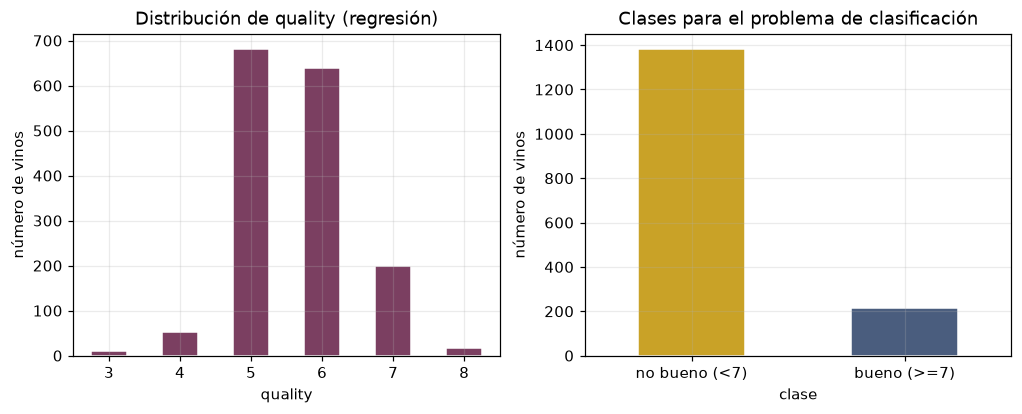

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
df["quality"].value_counts().sort_index().plot.bar(ax=ax[0], color="#7b3f61", edgecolor="white")
ax[0].set_title("Distribución de quality (regresión)")
ax[0].set_xlabel("quality"); ax[0].set_ylabel("número de vinos")

(df["quality"] >= 7).map({True: "bueno (>=7)", False: "no bueno (<7)"}) \
    .value_counts().plot.bar(ax=ax[1], color=["#c9a227", "#4a5d7e"], edgecolor="white")
ax[1].set_title("Clases para el problema de clasificación")
ax[1].set_xlabel("clase"); ax[1].set_ylabel("número de vinos")
for a in ax:
    a.tick_params(axis="x", rotation=0)


## 1. Regresión: predecir `quality`

Partición 80 / 20 con `random_state=42`. Se ajusta una regresión lineal por mínimos
cuadrados ordinarios (OLS) sobre las 11 variables. 

In [9]:
X = df.drop(columns=["quality"])
y = df["quality"]                     # variable continua (ordinal 3..8)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED)

print("Entrenamiento:", X_train.shape, " Prueba:", X_test.shape)
print("Media de y en entrenamiento: %.4f | media de y en prueba: %.4f"
      % (y_train.mean(), y_test.mean()))

Entrenamiento: (1279, 11)  Prueba: (320, 11)
Media de y en entrenamiento: 5.6239 | media de y en prueba: 5.6844


In [10]:
reg = LinearRegression().fit(X_train, y_train)
y_pred = reg.predict(X_test)

rmse   = mean_squared_error(y_test, y_pred) ** 0.5      # RMSE = sqrt(MSE)
mae    = mean_absolute_error(y_test, y_pred)
r2     = r2_score(y_test, y_pred)
r2_tr  = reg.score(X_train, y_train)

# Línea base: predecir SIEMPRE el promedio del conjunto de entrenamiento
y_base = np.full(len(y_test), y_train.mean())
rmse_base = mean_squared_error(y_test, y_base) ** 0.5
mae_base  = mean_absolute_error(y_test, y_base)
r2_base   = r2_score(y_test, y_base)

res_reg = pd.DataFrame({
    "modelo": ["Regresión lineal (OLS)", "Predecir siempre el promedio"],
    "RMSE": [rmse, rmse_base],
    "MAE": [mae, mae_base],
    "R2": [r2, r2_base],
}).set_index("modelo")
print("R2 en entrenamiento (OLS): %.4f\n" % r2_tr)
print(res_reg.round(4).to_string())
print("\nMejora en RMSE: %.2f %% | el promedio usado fue %.4f"
      % (100 * (1 - rmse / rmse_base), y_train.mean()))

R2 en entrenamiento (OLS): 0.3480

                                RMSE     MAE      R2
modelo                                              
Regresión lineal (OLS)        0.6245  0.5035  0.4032
Predecir siempre el promedio  0.8107  0.6853 -0.0056

Mejora en RMSE: 22.96 % | el promedio usado fue 5.6239


### Lectura de los resultados

- **Regresión lineal:** RMSE  0.62 y R^2  0.40. Es decir, explica ~40 % de la
  varianza de `quality` en prueba y se equivoca en promedio ~0.62 puntos de una
  escala donde la desviación estándar es de 0.81.
- **Predecir siempre el promedio:** RMSE ~ 0.81 y R^2 ~ 0.00 (de hecho ligeramente
  negativo, porque el promedio se calculó en entrenamiento y no en prueba). Es el
  punto de referencia obligado: **R^2 = 0 significa exactamente "no mejor que la
  media"**.
- Conclusión parcial: la recta **sí aprende algo** (reduce el RMSE ~23 % respecto al
  promedio), pero está lejos de ser un buen predictor: el vino es un fenómeno
  ruidoso y varias variables relevantes (aroma, taninos, gusto del catador) no
  están en la tabla.

La siguiente celda muestra de dónde viene la mejora: `alcohol` y `volatile_acidity`
son las variables que más pesan, algo consistente con la enología.

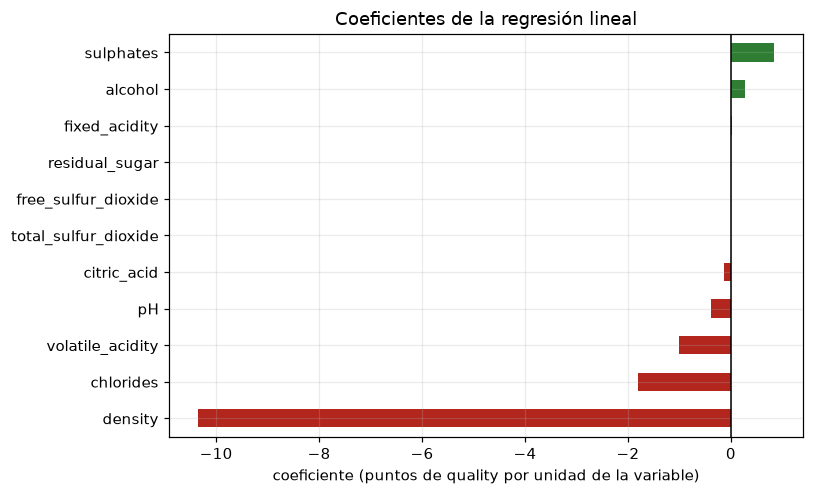

Figura guardada: figuras/02_coeficientes.png


In [8]:
coef = pd.DataFrame({"coeficiente": reg.coef_}, index=X.columns).sort_values("coeficiente")
fig, ax = plt.subplots(figsize=(7.5, 4.6))
coef["coeficiente"].plot.barh(ax=ax, color=np.where(coef["coeficiente"] > 0, "#2e7d32", "#b3261e"))
ax.axvline(0, color="black", lw=1)
ax.set_title("Coeficientes de la regresión lineal")
ax.set_xlabel("coeficiente (puntos de quality por unidad de la variable)")
print("Figura guardada:", guardar(fig, "coeficientes"))

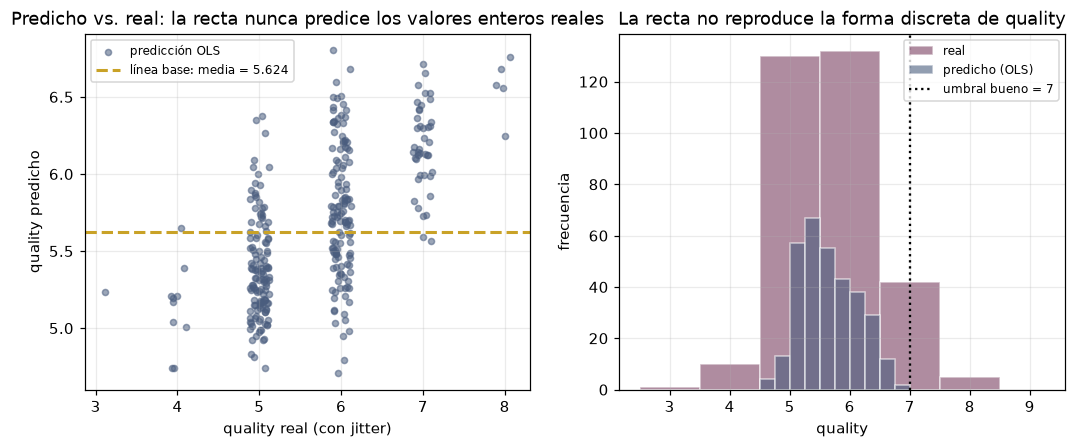

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))

# Predicho vs. real (con jitter vertical, porque los valores reales son enteros)
ax[0].scatter(y_test + np.random.uniform(-0.12, 0.12, len(y_test)), y_pred,
              s=16, alpha=0.55, color="#4a5d7e", label="predicción OLS")
ax[0].axhline(y_train.mean(), color="#c9a227", ls="--", lw=2,
              label="línea base: media = %.3f" % y_train.mean())
ax[0].set_xlabel("quality real (con jitter)"); ax[0].set_ylabel("quality predicho")
ax[0].set_title("Predicho vs. real: la recta nunca predice los valores enteros reales")
ax[0].legend(fontsize=8)

# Distribución de predicciones vs. valores reales
ax[1].hist(y_test, bins=np.arange(2.5, 9.5, 1), alpha=0.6, color="#7b3f61",
           label="real", align="mid", edgecolor="white")
ax[1].hist(y_pred, bins=np.arange(2.5, 9.5, 0.25), alpha=0.6, color="#4a5d7e",
           label="predicho (OLS)", edgecolor="white")
ax[1].axvline(7, color="black", ls=":", lw=1.5, label="umbral bueno = 7")
ax[1].set_xlabel("quality"); ax[1].set_ylabel("frecuencia")
ax[1].set_title("La recta no reproduce la forma discreta de quality")
ax[1].legend(fontsize=8)


## 2. Clasificación: `bueno = quality >= 7`

El experimento clave de la tarea: **se usa el mismo tipo de modelo** (regresión
lineal, ajustada ahora contra una columna 0/1) y se decide con la regla
`y_hat >= 0.5`. Todas las cifras que siguen son sobre el **conjunto de prueba**.

In [12]:
y_bin = (df["quality"] >= 7).astype(int)      # 1 = bueno, 0 = no bueno

print("Vinos buenos en todo el dataset: %d de %d = %.2f %%"
      % (y_bin.sum(), len(y_bin), 100 * y_bin.mean()))

# Misma partición: mismo random_state y mismo orden de filas
X_tr, X_te, b_tr, b_te = train_test_split(X, y_bin, test_size=0.20, random_state=SEED)

print("Entrenamiento: %d buenos de %d (%.2f %%)"
      % (b_tr.sum(), len(b_tr), 100 * b_tr.mean()))
print("Prueba:        %d buenos de %d (%.2f %%)"
      % (b_te.sum(), len(b_te), 100 * b_te.mean()))

# Verificación: el 20 % de prueba debe ser exactamente el mismo de la sección 1
print("\n¿Mismo conjunto de prueba que en la sección 1?", list(X_te.index) == list(X_test.index))

Vinos buenos en todo el dataset: 217 de 1599 = 13.57 %
Entrenamiento: 170 buenos de 1279 (13.29 %)
Prueba:        47 buenos de 320 (14.69 %)

¿Mismo conjunto de prueba que en la sección 1? True


In [13]:
# La MISMA regresión lineal, ahora sobre la columna binaria
reg_bin = LinearRegression().fit(X_tr, b_tr)
phi = reg_bin.predict(X_te)                   # "probabilidades" implícitas

y_hat_cls = (phi >= 0.5).astype(int)          # regla pedida: bueno si phi >= 0.5

acc_modelo = accuracy_score(b_te, y_hat_cls)
acc_base   = accuracy_score(b_te, np.zeros(len(b_te)))   # predecir siempre "no bueno"

fuera = int(((phi < 0) | (phi > 1)).sum())
debajo = int((phi < 0).sum())
arriba = int((phi > 1).sum())

res_cls = pd.DataFrame({
    "estrategia": ["Regresión lineal con umbral 0.5", "Predecir siempre no bueno"],
    "aciertos": [int((y_hat_cls == b_te).sum()), int((b_te == 0).sum())],
    "total": [len(b_te), len(b_te)],
    "exactitud": [acc_modelo, acc_base],
}).set_index("estrategia")
print(res_cls.assign(exactitud=lambda d: (100 * d["exactitud"]).round(2)).to_string())
print("\nExactitud del modelo          : %.4f  (%.2f %%)" % (acc_modelo, 100 * acc_modelo))
print("Exactitud de \"siempre no bueno\": %.4f  (%.2f %%)" % (acc_base, 100 * acc_base))
print("Diferencia (modelo - base)     : %+.4f" % (acc_modelo - acc_base))
print("\nPredicciones fuera de [0, 1]   : %d de %d  (%.2f %%)"
      % (fuera, len(phi), 100 * fuera / len(phi)))
print("   por debajo de 0 : %d" % debajo)
print("   por encima de 1 : %d" % arriba)
print("Rango de las predicciones: [%.4f, %.4f]" % (phi.min(), phi.max()))

                                 aciertos  total  exactitud
estrategia                                                 
Regresión lineal con umbral 0.5       276    320      86.25
Predecir siempre no bueno             273    320      85.31

Exactitud del modelo          : 0.8625  (86.25 %)
Exactitud de "siempre no bueno": 0.8531  (85.31 %)
Diferencia (modelo - base)     : +0.0094

Predicciones fuera de [0, 1]   : 82 de 320  (25.62 %)
   por debajo de 0 : 82
   por encima de 1 : 0
Rango de las predicciones: [-0.1504, 0.5439]


### Matriz de confusión y métricas por clase

La exactitud global es engañosa con clases desbalanceadas: 86.25 % suena bien, pero
**85.31 % se obtiene sin modelo alguno**, simplemente diciendo "no bueno" a todo.
La matriz de confusión expone el problema real.

In [14]:
cm = confusion_matrix(b_te, y_hat_cls)
tn, fp, fn, tp = cm.ravel()

print("Matriz de confusión (filas = real, columnas = predicho)")
print(pd.DataFrame(cm, index=["real: no bueno", "real: bueno"],
                   columns=["pred: no bueno", "pred: bueno"]).to_string())
print()
print("Verdaderos negativos (TN): %3d   Falsos positivos (FP): %3d" % (tn, fp))
print("Falsos negativos     (FN): %3d   Verdaderos positivos (TP): %3d" % (fn, tp))
print()
print("Sensibilidad / recall (detecta buenos): %.4f   -> se le escapan %d de %d buenos"
      % (recall_score(b_te, y_hat_cls, zero_division=0), fn, fn + tp))
print("Precisión (cuando dice bueno, acierta): %.4f" % precision_score(b_te, y_hat_cls, zero_division=0))
print("Especificidad (detecta no buenos)     : %.4f" % (tn / (tn + fp)))
print("F1 de la clase \"bueno\"              : %.4f" % f1_score(b_te, y_hat_cls, zero_division=0))

resumen_cls = pd.DataFrame({
    "valor": [acc_modelo, acc_base, recall_score(b_te, y_hat_cls, zero_division=0),
              precision_score(b_te, y_hat_cls, zero_division=0),
              f1_score(b_te, y_hat_cls, zero_division=0), fuera, len(phi)],
}, index=["exactitud modelo (umbral 0.5)", "exactitud siempre no bueno", "recall clase bueno",
          "precisión clase bueno", "F1 clase bueno",
          "predicciones fuera de [0,1]", "total de predicciones en prueba"]).round(4)
resumen_cls

Matriz de confusión (filas = real, columnas = predicho)
                pred: no bueno  pred: bueno
real: no bueno             271            2
real: bueno                 42            5

Verdaderos negativos (TN): 271   Falsos positivos (FP):   2
Falsos negativos     (FN):  42   Verdaderos positivos (TP):   5

Sensibilidad / recall (detecta buenos): 0.1064   -> se le escapan 42 de 47 buenos
Precisión (cuando dice bueno, acierta): 0.7143
Especificidad (detecta no buenos)     : 0.9927
F1 de la clase "bueno"              : 0.1852


,valor
exactitud modelo (umbral 0.5),0.8625
exactitud siempre no bueno,0.8531
recall clase bueno,0.1064
precisión clase bueno,0.7143
F1 clase bueno,0.1852
"predicciones fuera de [0,1]",82.0000
total de predicciones en prueba,320.0000


### El 0.5 no es el umbral correcto para decidir clases

Además del desbalance, hay un detalle técnico: cuando el objetivo es 0/1 y se
minimiza error cuadrático, el umbral que **minimiza los errores de clasificación** no
es 0.5: hay que buscarlo aparte. Veamos qué umbral maximiza la exactitud en prueba.

In [15]:
umbrales = np.linspace(0.0, 1.0, 501)
exactitudes = np.array([accuracy_score(b_te, (phi >= t).astype(int)) for t in umbrales])
mejor = umbrales[exactitudes.argmax()]

print("Umbral 0.50 -> exactitud %.4f" % acc_modelo)
print("Mejor umbral en prueba: %.3f -> exactitud %.4f" % (mejor, exactitudes.max()))
print("Umbral que iguala a \"siempre no bueno\" (%.4f): phi >= %.4f"
      % (acc_base, phi.max()))
print("Nota: con %.2f %% de buenos, predecir bueno casi siempre cuesta más de lo que aporta."
      % (100 * b_te.mean()))

Umbral 0.50 -> exactitud 0.8625
Mejor umbral en prueba: 0.440 -> exactitud 0.8719
Umbral que iguala a "siempre no bueno" (0.8531): phi >= 0.5439
Nota: con 14.69 % de buenos, predecir bueno casi siempre cuesta más de lo que aporta.


De 320 predicciones, 82 quedan fuera de [0, 1] -> 25.6 por ciento.


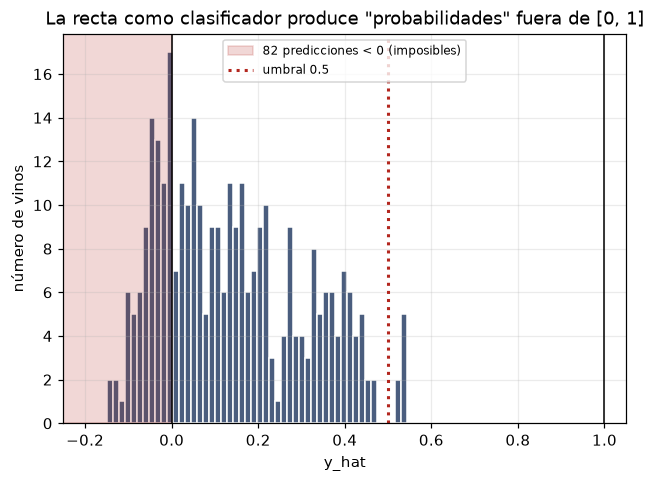

In [17]:
fig, ax = plt.subplots(figsize=(6.6, 4.6))
ax.hist(phi, bins=50, color="#4a5d7e", edgecolor="white")
ax.axvspan(-0.25, 0.0, color="#b3261e", alpha=0.18, label="%d predicciones < 0 (imposibles)" % debajo)
ax.axvline(0.5, color="#b3261e", ls=":", lw=2, label="umbral 0.5")
ax.axvline(0, color="black", lw=1); ax.axvline(1, color="black", lw=1)
ax.set_xlim(-0.25, 1.05)
ax.set_xlabel("y_hat"); ax.set_ylabel("número de vinos")
ax.set_title("La recta como clasificador produce \"probabilidades\" fuera de [0, 1]")
ax.legend(fontsize=8)
print("De %d predicciones, %d quedan fuera de [0, 1] -> %.1f por ciento."
      % (len(phi), fuera, 100 * fuera / len(phi)))

**Contexto: no es un accidente de esta partición.** Repitiendo el mismo montaje con
validación cruzada de 5 particiones sobre todo el dataset, la exactitud del modelo
queda pegada a la línea base y las predicciones siguen saliéndose del rango válido.

In [18]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

acc_cv, base_cv, fuera_cv = [], [], []
for i_tr, i_te in kf.split(df):
    m = LinearRegression().fit(X.iloc[i_tr], y_bin.iloc[i_tr])
    p = m.predict(X.iloc[i_te])
    acc_cv.append(accuracy_score(y_bin.iloc[i_te], (p >= 0.5).astype(int)))
    base_cv.append(accuracy_score(y_bin.iloc[i_te], np.zeros(len(i_te))))
    fuera_cv.append(100 * np.mean((p < 0) | (p > 1)))

print("Exactitud del modelo:", np.round(acc_cv, 4), "-> media %.4f" % np.mean(acc_cv))
print("Exactitud \"siempre no bueno\":", np.round(base_cv, 4), "-> media %.4f" % np.mean(base_cv))
print("Diferencia media     : %+.4f" % (np.mean(acc_cv) - np.mean(base_cv)))
print("Fuera de [0,1] por particion:", np.round(fuera_cv, 2), "-> media %.2f por ciento" % np.mean(fuera_cv))

# Contraste: la regresión sobre quality sí aporta sobre su línea base
r2_cv = cross_val_score(LinearRegression(), X, y, cv=kf, scoring="r2")
rmse_cv = -cross_val_score(LinearRegression(), X, y, cv=kf, scoring="neg_root_mean_squared_error")
base_rmse_cv = [mean_squared_error(y.iloc[i_te], np.full(len(i_te), y.iloc[i_tr].mean())) ** 0.5
                for i_tr, i_te in kf.split(df)]
print("Sección 1 - R2 por partición (5-fold):  ", np.round(r2_cv, 4), "-> media %.4f" % r2_cv.mean())
print("Sección 1 - RMSE modelo: %.4f | RMSE promedio: %.4f | mejora: %.2f %%"
      % (rmse_cv.mean(), np.mean(base_rmse_cv), 100 * (1 - rmse_cv.mean() / np.mean(base_rmse_cv))))

Exactitud del modelo: [0.8625 0.875  0.8625 0.8625 0.8903] -> media 0.8706
Exactitud "siempre no bueno": [0.8531 0.8688 0.8625 0.8594 0.8777] -> media 0.8643
Diferencia media     : +0.0063
Fuera de [0,1] por particion: [25.62 25.94 29.69 25.94 22.88] -> media 26.01 por ciento
Sección 1 - R2 por partición (5-fold):   [0.4032 0.2721 0.2729 0.3373 0.4267] -> media 0.3424
Sección 1 - RMSE modelo: 0.6536 | RMSE promedio: 0.8075 | mejora: 19.06 %


## 3. Conclusión

Para elegir el modelo adecuado al problema, primero hay que tener claro qué queremos responder y cómo mediremos el éxito:

### 1. Regresión (Estimar una nota)

* Objetivo: Predecir el valor exacto de `quality`. Aquí importa **cuánto** te equivocas en cada estimación.
* Resultado: La recta funciona bien porque reduce el error respecto a simplemente adivinar el promedio.
* Limitación: `quality` es una escala de pasos discretos y hay factores que el modelo no conoce, por lo que tiene un techo claro de precisión.

### 2. Clasificación (Decidir "Bueno" o "No bueno")

* Objetivo: Decidir si un vino supera un umbral para considerarse "bueno". Aquí solo importa **si aciertas o fallas** la etiqueta.
* Resultado: La misma recta **fracasa**. Como la gran mayoría de los vinos no son "buenos", el modelo casi no aporta valor frente a la opción trivial de decir que *ningún* vino es bueno.

¿Por qué falla la clasificación?
1. No da probabilidades, la recta puede devolver cualquier numero, incluso negativos (que no tiene sentido al buscar probabilidades).
2. Casi no detecta los vinos buenos: Las predicciones qeudan comprimidas en un rango bajo. Al usar el limite de 0.5, el modelo aprende a no etiqueta casi ningun vino como bueno.
3. Mide el error erroneamente: La recta intenta no cometer desviaciones grandes en valor numérico, mientras que la clasificación solo importa si la etiqueta final es correcta o no.

**En resumen:** La recta es una buena herramienta para estimar la nota continua de `quality`, pero una mala opción para decidir "bueno / no bueno". Para clasificar se deben usar modelos diseñados para dar probabilidades (como la regresión logística) y evaluar si realmente estamos detectando la clase que nos interesa.